![python](img/python_logo.png)

**Examinador:** Elvis Pachacama
**Recopilado por:** Pablo Aguilar
* Repositorio: <a href="https://github.com/Exosphere-Idyllic/Machine-Learning/blob/master/Hola%20mundo.ipynb">GitHub</a>
* URL: https://github.com/Exosphere-Idyllic/Machine-Learning

##Examen Parcial I

## Configuración inicial

Se define aquí las herramientas para el EDA y el resto del proyecto

In [8]:
## Descarga y manejo de archivos
import kagglehub
import os
import io
import zipfile

## EDA
import numpy as np
import pandas as pd

## Visualización
import matplotlib.pyplot as plt

## Estadística 
from scipy import stats

## Preprocesamiento
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

## Selección de atributos
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, RFE
from sklearn.linear_model import LinearRegression, Lasso, Ridge

## Modelo
from sklearn.linear_model import LinearRegression

## Métricas
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score, mean_absolute_percentage_error

## Reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


### Descarga del dataset vía código

In [9]:
path = kagglehub.dataset_download("mirichoi0218/insurance")
print("Path to dataset files:", path)

# Localizar el CSV dentro del directorio descargado
csv_path = os.path.join(path, "insurance.csv")
df = pd.read_csv(csv_path)

print(f"Dimensiones: {df.shape}")
df.head()

Path to dataset files: C:\Users\USER\.cache\kagglehub\datasets\mirichoi0218\insurance\versions\1
Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Carga y comprensión


 — Estructura del Dataset

 
Dimensiones: El dataset contiene 1338 registros (filas) y 7 columnas.

Tipos de datos:

int64: age, children (variables numéricas discretas).

float64: bmi, charges (variables numéricas continuas).

object (str): sex, smoker, region (variables categóricas).

Memoria: 73.3 KB, lo que indica un dataset ligero, ideal para procesar en memoria sin problemas.

Valores no nulos: Todas las columnas tienen 1338 valores no nulos, lo que confirma a simple vista que no hay valores faltantes.

Observaciones clave:

charges (Variable Objetivo): Tiene una media de ~13,270, pero su desviación estándar es muy alta (~12,110) y su máximo es 63,770. Esto sugiere una distribución asimétrica (sesgada a la derecha), lo cual es común en costos médicos. Será importante revisar esto en el EDA.

bmi: La media (30.66) está en el rango de sobrepeso/obesidad según la OMS. El máximo (53.13) indica posibles valores atípicos (outliers) que deberán tratarse.

Variables categóricas: sex, smoker y region tienen pocas categorías (2, 2 y 4 respectivamente), lo que las hace candidatas ideales para One-Hot Encoding.

age: Rango de 18 a 64 años, sin valores extraños.

In [10]:
df.info()
display(df.describe(include="all"))
print("Duplicados:", df.duplicated().sum())
print("Nulos:\n", df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


Duplicados: 1
Nulos:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


EDA y calidad de datos

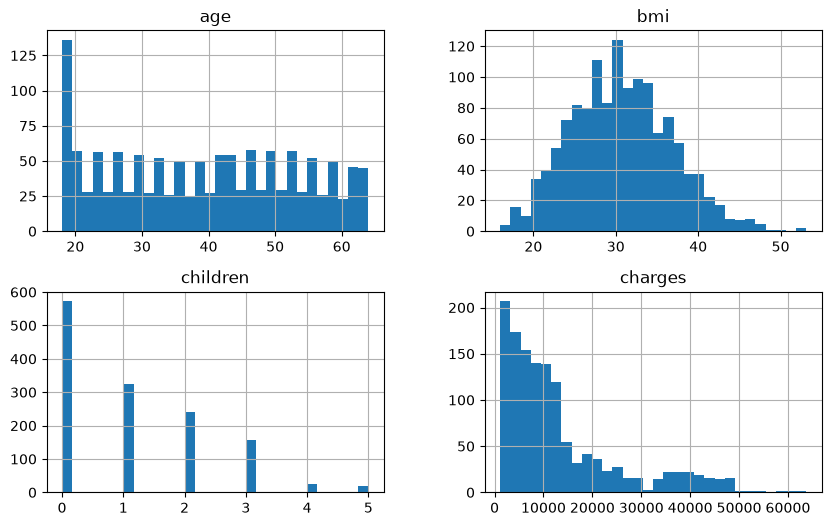

Asimetría de charges: 1.5136902413349014


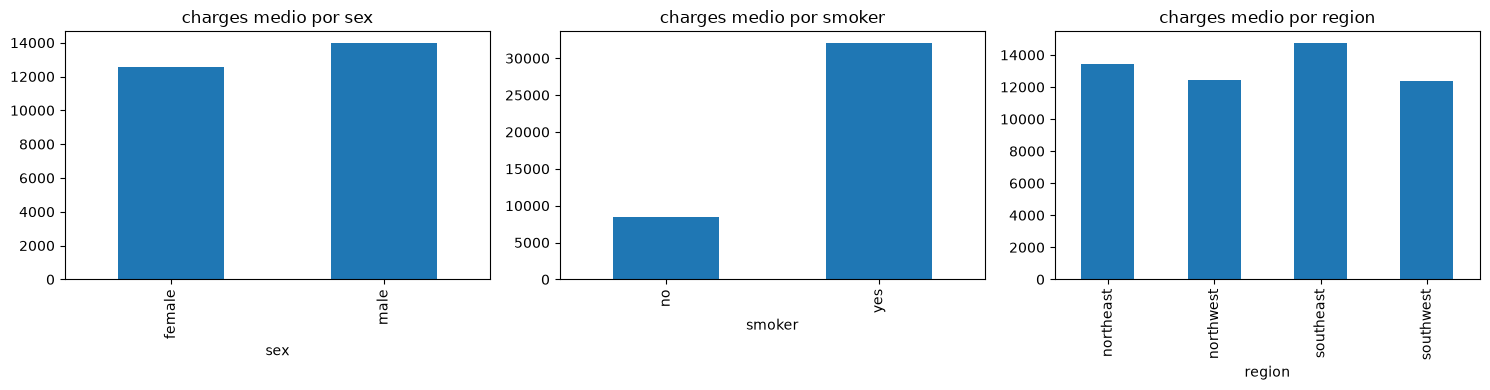

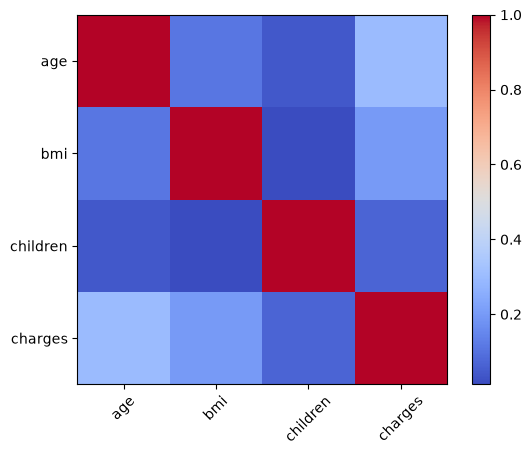

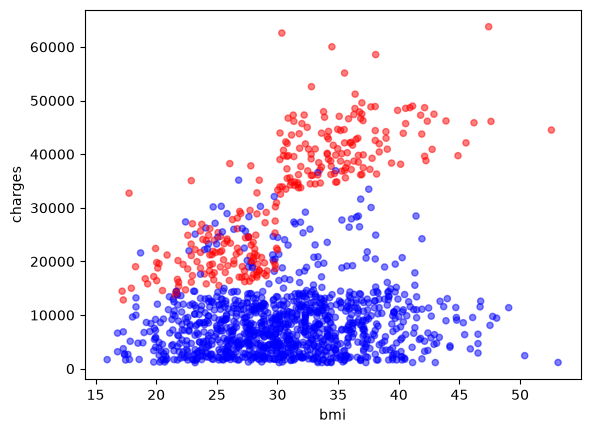

In [11]:
df = df.drop_duplicates().reset_index(drop=True)   # hay 1 duplicado en este dataset

num_cols = ["age", "bmi", "children", "charges"]
cat_cols = ["sex", "smoker", "region"]

df[num_cols].hist(bins=30, figsize=(10, 6)); plt.show()
print("Asimetría de charges:", stats.skew(df["charges"]))

# charges promedio por categoría
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, cat_cols):
    df.groupby(c)["charges"].mean().plot(kind="bar", ax=a, title=f"charges medio por {c}")
plt.tight_layout(); plt.show()

# correlaciones
corr = df[num_cols].corr()
plt.imshow(corr, cmap="coolwarm"); plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45); plt.yticks(range(len(num_cols)), num_cols)
plt.show()

# el hallazgo clave: smoker vs bmi
df.plot.scatter(x="bmi", y="charges", c=(df["smoker"] == "yes").map({True: "red", False: "blue"}), alpha=.5)
plt.show()

Detección de outliers

age: 0 outliers (IQR)
bmi: 9 outliers (IQR)
children: 0 outliers (IQR)
charges: 139 outliers (IQR)
Outliers Z>3: {'bmi': 4, 'charges': 7}


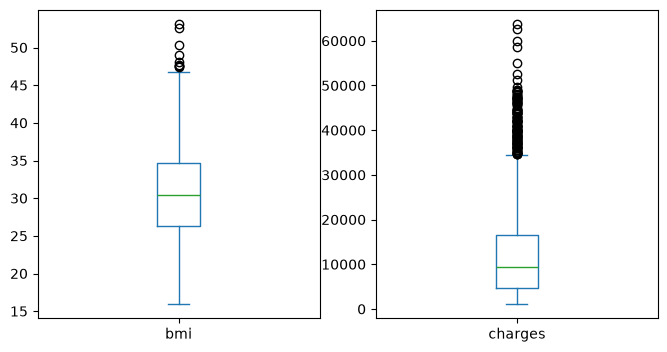

In [12]:
def iqr_mask(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

for c in ["age", "bmi", "children", "charges"]:
    print(f"{c}: {iqr_mask(df[c]).sum()} outliers (IQR)")

z = np.abs(stats.zscore(df[["bmi", "charges"]]))
print("Outliers Z>3:", pd.Series((z > 3).sum(axis=0), index=["bmi", "charges"]).to_dict())

df[["bmi", "charges"]].plot(kind="box", subplots=True, figsize=(8, 4)); plt.show()

Preparación de variables y estandarización

In [13]:
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["smoker"])

num_f, bin_f, cat_f = ["age", "bmi", "children"], ["sex", "smoker"], ["region"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_f),
    ("bin", OneHotEncoder(drop="if_binary"), bin_f),
    ("cat", OneHotEncoder(drop="first"), cat_f),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
feat_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_p, columns=feat_names)
X_train_df.head()

,num__age,num__bmi,num__children,bin__sex_male,bin__smoker_yes,cat__region_northwest,cat__region_southeast,cat__region_southwest
0,0.209157,-0.959818,0.769598,0.0,0.0,1.0,0.0,0.0
1,1.775700,1.370265,-0.076801,1.0,0.0,0.0,1.0,0.0
2,0.992428,-0.220931,-0.923201,1.0,0.0,0.0,1.0,0.0
3,-0.146876,0.882057,-0.923201,1.0,0.0,0.0,1.0,0.0
4,-1.499800,1.225611,-0.923201,0.0,0.0,0.0,1.0,0.0


Selección de atributos

In [14]:
# 1. Filtro: F-test
skb = SelectKBest(f_regression, k="all").fit(X_train_df, y_train)
# 2. Filtro: información mutua
mi = mutual_info_regression(X_train_df, y_train, random_state=RANDOM_STATE)
# 3. Wrapper: RFE
rfe = RFE(LinearRegression(), n_features_to_select=5).fit(X_train_df, y_train)
# 4. Embebido: Lasso
lasso = Lasso(alpha=10).fit(X_train_df, y_train)

sel = pd.DataFrame({"F": skb.scores_, "MI": mi, "RFE": rfe.support_,
                    "Lasso_coef": lasso.coef_}, index=feat_names).round(3)
display(sel.sort_values("F", ascending=False))

,F,MI,RFE,Lasso_coef
bin__smoker_yes,1632.224,0.361,True,23682.390
num__age,97.155,1.381,True,3585.888
num__bmi,35.791,0.105,True,1991.156
num__children,6.071,0.138,False,729.098
cat__region_southeast,5.920,0.020,True,-1017.423
cat__region_southwest,2.585,0.012,True,-863.466
bin__sex_male,1.467,0.139,False,-215.058
cat__region_northwest,0.875,0.043,False,-197.388


Validación

In [15]:
pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
rmse = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
print(f"R² CV: {r2.mean():.3f} ± {r2.std():.3f}")
print(f"RMSE CV: {rmse.mean():,.0f} ± {rmse.std():,.0f}")

R² CV: 0.722 ± 0.036
RMSE CV: 6,297 ± 629


Entrenamiento

In [16]:
pipe.fit(X_train, y_train)
coefs = pd.Series(pipe.named_steps["model"].coef_, index=feat_names)
print("Intercepto:", pipe.named_steps["model"].intercept_)
display(coefs.sort_values(key=abs, ascending=False))

Intercepto: 9283.851527009758


bin__smoker_yes          23750.032145
num__age                  3594.126588
num__bmi                  2012.606363
cat__region_southeast    -1193.734426
cat__region_southwest    -1031.822157
num__children              739.762046
cat__region_northwest     -361.196690
bin__sex_male             -257.961317
dtype: float64

Evaluación

,Modelo,MAE,RMSE,R²,MAPE
0,Lineal base,3592.793,5086.880,0.820,0.347
1,Lineal + log(charges),3976.019,7905.986,0.566,0.256


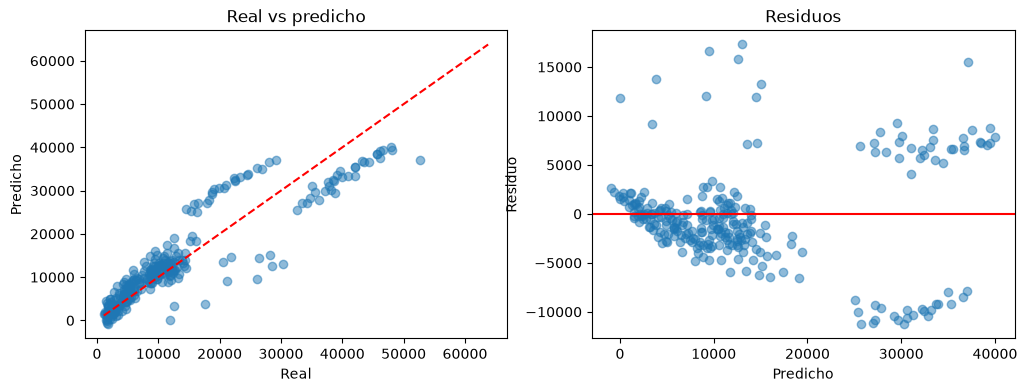

In [17]:
def evaluar(modelo, nombre):
    pred = modelo.predict(X_test)
    return {"Modelo": nombre,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R²": r2_score(y_test, pred),
            "MAPE": mean_absolute_percentage_error(y_test, pred)}

res = [evaluar(pipe, "Lineal base")]

# Mejora: log del objetivo (corrige el sesgo de charges)
from sklearn.compose import TransformedTargetRegressor
pipe_log = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocessor), ("model", LinearRegression())]),
    func=np.log1p, inverse_func=np.expm1).fit(X_train, y_train)
res.append(evaluar(pipe_log, "Lineal + log(charges)"))

display(pd.DataFrame(res).round(3))

# Gráficos de diagnóstico
pred = pipe.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_test, pred, alpha=.5); ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set(xlabel="Real", ylabel="Predicho", title="Real vs predicho")
ax[1].scatter(pred, y_test - pred, alpha=.5); ax[1].axhline(0, color="r")
ax[1].set(xlabel="Predicho", ylabel="Residuo", title="Residuos")
plt.show()

Predicción con nuevos datos

In [18]:
nuevos = pd.DataFrame({
    "age": [25, 45, 60],
    "sex": ["female", "male", "male"],
    "bmi": [22.5, 31.0, 35.2],
    "children": [0, 2, 3],
    "smoker": ["no", "yes", "no"],
    "region": ["southwest", "northeast", "southeast"],
})
nuevos["charges_estimado"] = pipe.predict(nuevos).round(2)
nuevos

,age,sex,bmi,children,smoker,region,charges_estimado
0,25,female,22.5,0,no,southwest,1216.23
1,45,male,31.0,2,yes,northeast,34922.97
2,60,male,35.2,3,no,southeast,15833.71
